# **Experiment Notebook**

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

---
## 0. Python Packages

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### Using the extended customised package

In [8]:
!pip install --no-deps --index-url https://test.pypi.org/simple/ aml-25741481==0.2.0

In [9]:
from aml_25741481 import compute_whi, whi_to_class, attach_future_target

---
## A. Project Description

In [10]:
business_use_case_description = """
Open-Meteo is enhancing its weather platform with AI-powered forecasting services. 
This project creates a machine learning model that forecasts the Weather Hazard Category (WHC), a 4-level 
risk classification (Low, Moderate, High, Extreme) indicating the severity of weather conditions and their impact on people,
infrastructure, and transportation, 7 days in advance for Sydney, NSW. The model will be made available as a REST API endpoint, 
enabling downstream applications (such as logistics planning, transportation operations, and public safety alerting) to get medium-term danger projections."""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [12]:
business_objectives = """
Accurate WHC projections enable transportation operators, event organizers, and infrastructure managers 
to plan for probable weather disruptions up to 7 days in advance, allowing for preventive steps such as 
postponing outdoor work and preparing emergency resources. Underestimating hazard severity (e.g., predicting "Low Risk" 
when actual conditions are "Extreme Risk") can lead to inadequate preparation for dangerous conditions, which is a more serious failure than overpredicting hazard (necessary but harmless caution).
This asymmetry should guide both metric selection and acceptable error tolerance."""

In [13]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [14]:
stakeholders_expectations_explanations = """
Third-party applications and organizations use Open-Meteo's API for infrastructure, transportation, and public safety planning tools, 
such as construction scheduling, aviation/marine operations, and local government hazard communication. Accurate prediction has an indirect 
impact on end users, such as people who rely on transportation apps for disruption warnings. Because this task involves safety-related decisions 
rather than recreational planning, missed "Extreme Risk" days are less acceptable. Stakeholders expect the model to be evaluated based on its performance in the highest-severity class, rather than overall accuracy."""

In [15]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data

In [16]:
daily_df = pd.read_parquet("../../data/interim/sydney_daily_weather.parquet")
daily_df = daily_df.sort_values("date").reset_index(drop=True)
print(daily_df.shape)
daily_df.head()

(4018, 8)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2015-01-01,23.129167,80.125000,9.466667,26.625000,0.0,37.4,0.0
1,2015-01-02,22.933333,84.958333,9.604167,86.541667,0.0,34.6,0.0
2,2015-01-03,23.754167,85.125000,10.687500,33.833333,0.0,45.4,0.0
3,2015-01-04,24.329167,80.291667,8.329167,52.500000,10.2,46.8,0.0
4,2015-01-05,21.708333,83.166667,10.679167,85.541667,0.5,32.0,0.0


### C.2 Define Target variable

In [17]:
target_definition_explanations = """
The Weather Hazard Category (WHC) is a four-class risk classification (Low, Moderate, High, and Extreme) 
based on a continuous Weather Hazard Index (WHI, 0-100) that considers precipitation, wind gusts, cloud cover, snowfall, 
and temperature variance using weighted hazard ratings. Wind and rain are significantly weighted (0.30 each), indicating their 
significant impact on transportation interruption and infrastructure risk. Predicting WHC 7 days ahead (vs. CCI's 3-day horizon) 
enables longer-term operational planning for weather-sensitive activities including construction, event logistics, and transportation."""

In [18]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [19]:
daily_df["whi_same_day"] = compute_whi(daily_df)
daily_df["whc_same_day"] = whi_to_class(daily_df["whi_same_day"])

daily_df = attach_future_target(daily_df, "whi_same_day", horizon_days=7, new_col="whi_target")
daily_df = attach_future_target(daily_df, "whc_same_day", horizon_days=7, new_col="whc_target")

# Verify the shift is correct
check_date = daily_df["date"].iloc[0]
target_val = daily_df.loc[daily_df["date"] == check_date, "whi_target"].values[0]
actual_7d_later = daily_df.loc[daily_df["date"] == check_date + pd.Timedelta(days=7), "whi_same_day"].values[0]
assert np.isclose(target_val, actual_7d_later), "Shift logic incorrect!"
print("Shift verified: whi_target correctly pulls WHI from 7 days ahead.")

daily_df = daily_df.dropna(subset=["whc_target"]).reset_index(drop=True)
daily_df["whc_target"] = daily_df["whc_target"].astype(int)

target_name = "whc_target"
print(f"Final dataset shape: {daily_df.shape}")
daily_df[["date", "whi_target", "whc_target"]].head()

Shift verified: whi_target correctly pulls WHI from 7 days ahead.
Final dataset shape: (4011, 12)


,date,whi_target,whc_target
0,2015-01-01,15.575000,0
1,2015-01-02,23.680000,0
2,2015-01-03,37.748333,1
3,2015-01-04,60.888333,2
4,2015-01-05,34.856667,1


In [20]:
target_name = 'whc_target'

### C.4 Explore Target variable

whc_target
Low Risk         1998
Moderate Risk    1846
High Risk         158
Extreme Risk        9
Name: count, dtype: int64

Class proportions:
whc_target
Low Risk         49.8%
Moderate Risk    46.0%
High Risk         3.9%
Extreme Risk      0.2%
Name: count, dtype: object


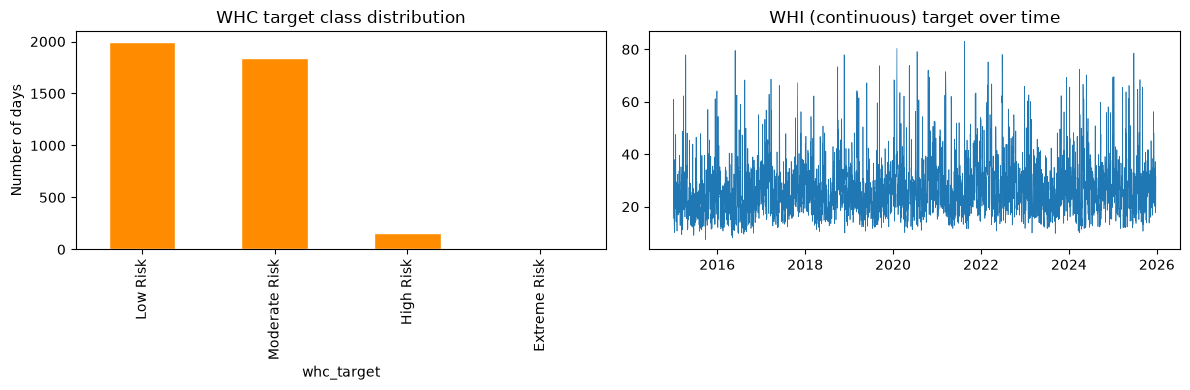

In [21]:
class_names = {0: "Low Risk", 1: "Moderate Risk", 2: "High Risk", 3: "Extreme Risk"}

counts = daily_df[target_name].value_counts().sort_index()
counts_labeled = counts.rename(index=class_names)
print(counts_labeled)
print("\nClass proportions:")
print((counts_labeled / counts_labeled.sum() * 100).round(1).astype(str) + "%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts_labeled.plot(kind="bar", ax=ax[0], color="darkorange", edgecolor="white")
ax[0].set_title("WHC target class distribution")
ax[0].set_ylabel("Number of days")

ax[1].plot(daily_df["date"], daily_df["whi_target"], linewidth=0.5)
ax[1].set_title("WHI (continuous) target over time")
plt.tight_layout()
plt.show()

In [22]:
target_distribution_explanations = """
provide a detailed analysis on the target variable, its distribution, limitations, issues, ...
"""

In [23]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `<wind_gusts_10m>`

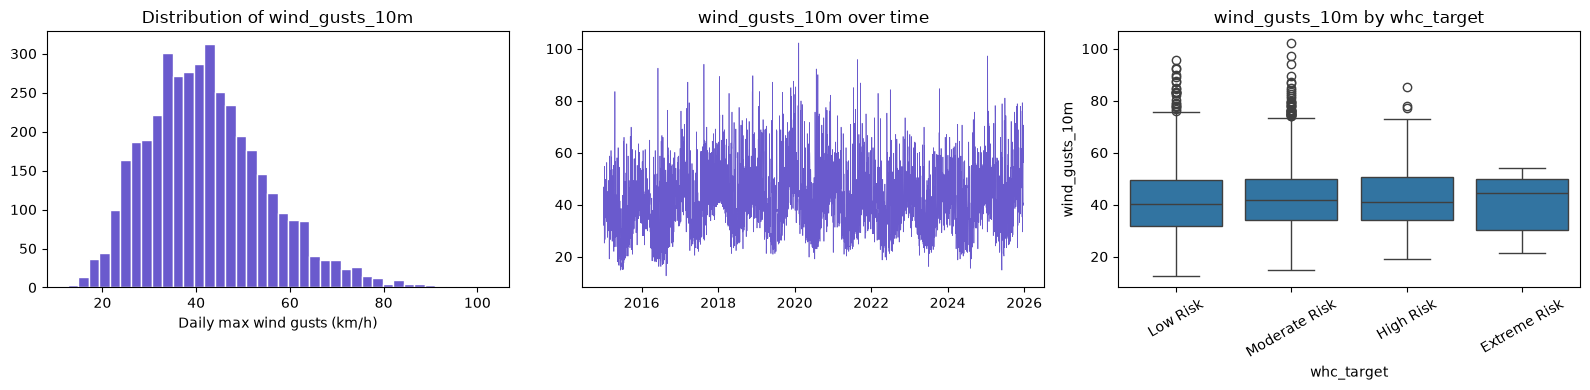

count    4011.000000
mean       42.159686
std        12.814918
min        12.600000
25%        33.100000
50%        41.000000
75%        49.700000
max       102.200000
Name: wind_gusts_10m, dtype: float64


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(daily_df["wind_gusts_10m"], bins=40, color="slateblue", edgecolor="white")
ax[0].set_title("Distribution of wind_gusts_10m")
ax[0].set_xlabel("Daily max wind gusts (km/h)")

ax[1].plot(daily_df["date"], daily_df["wind_gusts_10m"], linewidth=0.5, color="slateblue")
ax[1].set_title("wind_gusts_10m over time")

sns.boxplot(x=daily_df[target_name].map(class_names), y=daily_df["wind_gusts_10m"], ax=ax[2], order=list(class_names.values()))
ax[2].set_title(f"wind_gusts_10m by {target_name}")
ax[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print(daily_df["wind_gusts_10m"].describe())

In [26]:
feature_1_insights = """
Distribution: Right-skewed - most days cluster between 30-50 km/h, with a long tail of occasional high-gust events up to ~100 km/h.

Time series: No clear trend or seasonality; gusts fluctuate consistently across the full period with sporadic spikes.

Relationship with target (whc_target): Median wind_gusts_10m stays fairly similar across risk categories (Low to Extreme Risk), but the 
number of high-end outliers decreases from Low Risk to Extreme Risk - suggesting wind_gusts alone has limited separating power between 
classes, though extreme values are somewhat more common in lower-risk categories (possibly reflecting when gusts co-occur with other 
calmer conditions).

Limitations:
- Weak visual separation between risk categories suggests wind_gusts_10m may not be a strong standalone predictor for whc_target; likely more 
  useful combined with other hazard-related features.
- Right skew and outliers (up to 102.2 km/h) may need capping/log transform for models sensitive to non-normal distributions.
- Overlapping IQRs across categories indicate potential class overlap, which could limit classification accuracy if used in isolation."""

In [27]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `\<precipitation>`

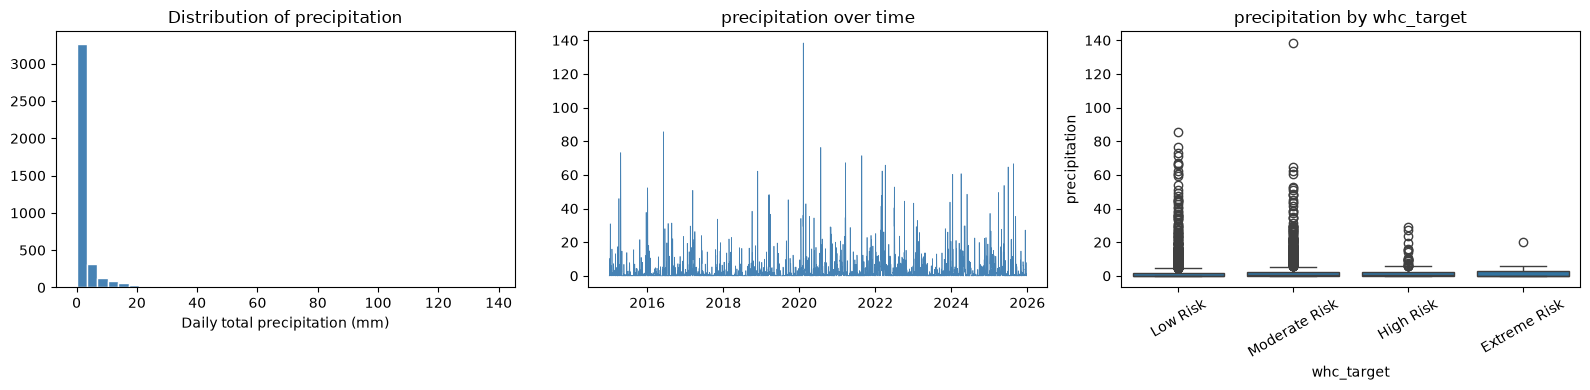

count    4011.000000
mean        2.747544
std         7.409919
min         0.000000
25%         0.000000
50%         0.200000
75%         2.000000
max       138.400000
Name: precipitation, dtype: float64


In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(daily_df["precipitation"], bins=40, color="steelblue", edgecolor="white")
ax[0].set_title("Distribution of precipitation")
ax[0].set_xlabel("Daily total precipitation (mm)")

ax[1].plot(daily_df["date"], daily_df["precipitation"], linewidth=0.5, color="steelblue")
ax[1].set_title("precipitation over time")

sns.boxplot(x=daily_df[target_name].map(class_names), y=daily_df["precipitation"], ax=ax[2], order=list(class_names.values()))
ax[2].set_title(f"precipitation by {target_name}")
ax[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print(daily_df["precipitation"].describe())

In [29]:
feature_2_insights = """
Distribution: Extremely right-skewed with a spike at zero - the vast majority of days have near-zero precipitation, with rare heavy 
rainfall outliers (up to 138.4mm).

Time series: No clear trend or seasonality; rainfall spikes appear sporadic and random across the full period.

Relationship with target (whc_target): Median precipitation is near zero across all risk categories, with almost all variation showing up 
as outliers rather than shifts in the median/IQR. Low and Moderate Risk categories contain the most high-precipitation outliers, while Extreme 
Risk shows almost none — suggesting precipitation alone doesn't strongly separate risk classes and may not be a primary driver of 
whc_target.

Limitations:
- Zero-inflated, heavily skewed distribution makes raw precipitation a poor fit for models assuming normality; consider log(1+x) transform 
  or a binary "is_rainy" indicator.
- Median/IQR near-identical across all classes limits standalone discriminative power for classification.
- Outlier-driven pattern suggests precipitation may only matter in combination with other features (e.g. wind) or during specific rare 
  extreme events, not as an independent signal."""

In [30]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

---
## D. Feature Selection

### D.1 Approach "\<Correlation Analysis (ordinal)>"

Correlation of each day-t raw weather variable with whc_target (day t+7, ordinal):
temperature_2m          0.113670
cloud_cover             0.055204
wind_gusts_10m          0.047689
relative_humidity_2m    0.034020
wind_speed_10m          0.022345
precipitation           0.005887
snowfall                     NaN
dtype: float64


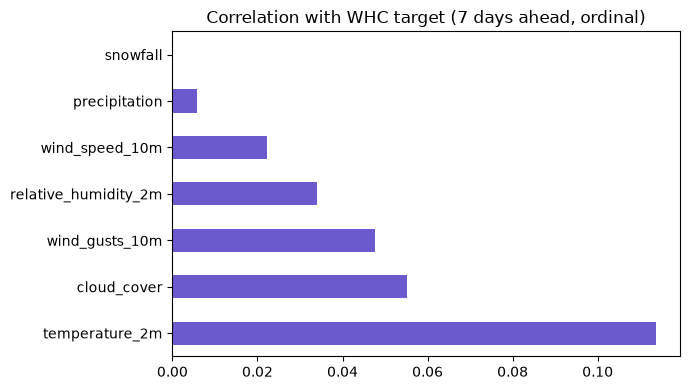

In [32]:
feature_cols_candidates = [
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "wind_gusts_10m", "cloud_cover", "precipitation", "snowfall",
]

# whc_target is ordinal (0=Low ... 3=Extreme), so correlation is still meaningful here,
# though weaker than for a continuous target since it's a coarse 4-bucket grouping.
correlations = daily_df[feature_cols_candidates].corrwith(daily_df[target_name].astype(float)).sort_values(key=abs, ascending=False)
print("Correlation of each day-t raw weather variable with whc_target (day t+7, ordinal):")
print(correlations)

correlations.plot(kind="barh", figsize=(7, 4), color="slateblue")
plt.title("Correlation with WHC target (7 days ahead, ordinal)")
plt.tight_layout()
plt.show()

In [33]:
feature_selection_1_insights = """
Approach: Correlation with whc_target (7 days ahead, ordinal)

I used Pearson correlation as a first-pass filter method to quickly rank each raw weather variable's linear relationship with whc_target 
(7 days ahead) before building any model. It's simple, fast, and gives an interpretable baseline to compare against more complex methods 
(e.g. feature importance) later.

Results: temperature_2m strongest (r=0.114), followed by cloud_cover (0.055), wind_gusts_10m (0.048), relative_humidity_2m (0.034), 
wind_speed_10m (0.022), precipitation (0.006, negligible). snowfall = NaN (zero variance), likely to be dropped.
"""

In [34]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "\<Random Forest Feature Importance>"

temperature_2m          0.214153
wind_gusts_10m          0.189604
wind_speed_10m          0.168150
relative_humidity_2m    0.149998
precipitation           0.148548
cloud_cover             0.129548
snowfall                0.000000
dtype: float64


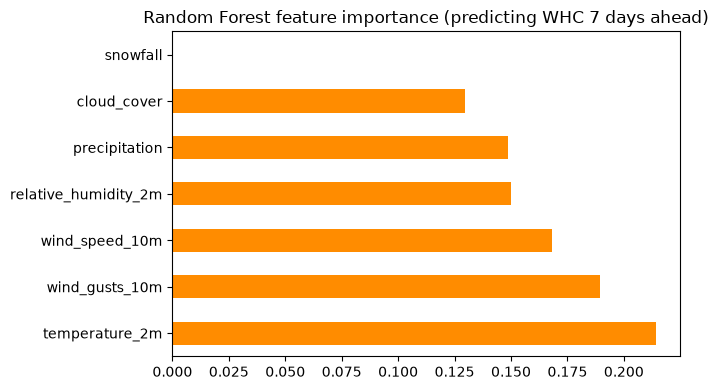

In [36]:
from sklearn.ensemble import RandomForestClassifier

X_temp = daily_df[feature_cols_candidates]
y_temp = daily_df[target_name]

rf_probe = RandomForestClassifier(
    n_estimators=200, max_depth=6, random_state=42, n_jobs=-1,
    class_weight="balanced",  # important given the severe class imbalance
)
rf_probe.fit(X_temp, y_temp)

importances = pd.Series(rf_probe.feature_importances_, index=feature_cols_candidates).sort_values(ascending=False)
print(importances)

importances.plot(kind="barh", figsize=(7, 4), color="darkorange")
plt.title("Random Forest feature importance (predicting WHC 7 days ahead)")
plt.tight_layout()
plt.show()

In [37]:
feature_selection_2_insights = """
Approach: Random Forest feature importance

I trained a Random Forest to predict whc_target (7 days ahead) and used its built-in feature importances as a second method, since it 
can capture non-linear relationships and interactions that plain correlation misses - useful here given how weak the correlations were.

Results: All 6 non-snowfall features contribute fairly evenly (0.13-0.21), unlike the correlation analysis which showed temperature 
dominating. temperature_2m is still highest (0.214), followed by wind_gusts_10m (0.190), wind_speed_10m (0.168), relative_humidity_2m 
(0.150), precipitation (0.149), and cloud_cover (0.130). snowfall = 0.000, confirming it should be dropped.
"""

In [38]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

## D.z Final Selection of Features

In [39]:
features_list = ["temperature_2m","relative_humidity_2m","wind_speed_10m","wind_gusts_10m","cloud_cover","precipitation"]

In [40]:
feature_selection_explanations = """
Random Forest importance showed all 6 features contribute fairly evenly (0.13-0.21) to predicting whc_target, unlike correlation which 
only flagged temperature as notably stronger — so all 6 are retained since importance captures non-linear/interaction effects correlation 
missed. snowfall is dropped due to zero variance (NaN correlation, 0.000 importance), confirming it carries no predictive value."""

In [41]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "\<duplicated dates or rows>"

In [43]:
df_clean = daily_df.copy()

print(f"Duplicate dates: {df_clean['date'].duplicated().sum()}")
print(f"Fully duplicate rows: {df_clean.duplicated().sum()}")
print(f"\nMissing values in selected features + target:\n{df_clean[features_list + [target_name]].isnull().sum()}")
print(f"\nDate range: {df_clean['date'].min()} to {df_clean['date'].max()}")
print(f"Total rows: {len(df_clean)}")

Duplicate dates: 0
Fully duplicate rows: 0

Missing values in selected features + target:
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
wind_gusts_10m          0
cloud_cover             0
precipitation           0
whc_target              0
dtype: int64

Date range: 2015-01-01 00:00:00 to 2025-12-24 00:00:00
Total rows: 4011


In [44]:
data_cleaning_1_explanations = """
Integrity check: 0 duplicate dates, 0 fully duplicate rows, 0 missing values across all selected features and target (2015-01-01 to 
2025-12-24, 4,011 rows).

Why this matters: duplicates could bias the model toward repeated observations or leak information across a chronological split, while 
missing values would need imputation/removal since most models can't handle NaNs directly. Confirming a clean dataset upfront avoids 
misattributing later model issues to data quality problems."""

In [45]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation "\<outliers>"

In [47]:
extreme_days = df_clean[df_clean[target_name] == 3][["date", "whi_target"] + features_list]
print(f"All {len(extreme_days)} Extreme Risk days:")
extreme_days

All 9 Extreme Risk days:


,date,whi_target,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation
103,2015-04-14,77.900000,17.125000,70.708333,6.604167,26.6,48.458333,0.0
514,2016-05-29,79.593333,13.041667,54.333333,10.066667,30.2,0.041667,0.0
1420,2018-11-21,77.950000,23.312500,68.000000,14.408333,49.7,80.875000,2.7
1858,2020-02-02,80.346667,25.733333,83.166667,13.820833,51.5,42.333333,6.0
2026,2020-07-19,79.140000,12.220833,73.166667,10.862500,32.4,36.083333,0.0
2420,2021-08-17,83.098333,12.858333,58.291667,13.475000,45.0,10.750000,0.0
2616,2022-03-01,75.215000,21.133333,87.000000,17.033333,44.6,88.833333,20.2
2733,2022-06-26,78.020000,12.379167,77.083333,8.475000,21.2,59.083333,0.0
3827,2025-06-24,78.556667,16.079167,67.333333,18.579167,54.0,25.541667,2.8


In [48]:
data_cleaning_2_explanations = """
Found only 9 "Extreme Risk" days (whc_target=3) out of 4,011 total rows (~0.2% of the data) - a severe class imbalance.

Why this matters: with so few examples, the model has very little signal to learn what distinguishes Extreme Risk from other classes, 
and standard training will likely under-predict or entirely ignore this class in favor of majority classes, since accuracy-driven learning 
naturally minimizes error on the dominant categories.

Impact/next steps: this needs explicit handling before modeling - options include class weighting, oversampling (e.g. SMOTE), or 
evaluating with metrics robust to imbalance (e.g. per-class precision/recall/F1, not just overall accuracy), since a model that 
never predicts "Extreme Risk" could still show misleadingly high accuracy while completely failing at the most safety-critical class.
"""

In [49]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation "\<dropping irrelevant features>"

In [51]:
modeling_df = df_clean[["date"] + features_list + [target_name]].copy()
print(modeling_df.shape)
modeling_df.head()

(4011, 8)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation,whc_target
0,2015-01-01,23.129167,80.125000,9.466667,37.4,26.625000,0.0,0
1,2015-01-02,22.933333,84.958333,9.604167,34.6,86.541667,0.0,0
2,2015-01-03,23.754167,85.125000,10.687500,45.4,33.833333,0.0,1
3,2015-01-04,24.329167,80.291667,8.329167,46.8,52.500000,10.2,2
4,2015-01-05,21.708333,83.166667,10.679167,32.0,85.541667,0.5,1


In [52]:
data_cleaning_3_explanations = """
Reduced the dataset to only date, the 6 selected features, and whi_target (4,011 rows), dropping unused intermediate/raw columns 
like snowfall.

Why this matters: removing unused columns eliminates any risk of accidental target leakage from intermediate variables and avoids 
feeding the model noise from features already shown to have no predictive value (snowfall). A clean, minimal feature set also makes 
the pipeline easier to audit and ensures the model only learns from deliberately selected variables."""

In [53]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

---
## F. Feature Engineering

### F.1 New Feature "\<lag_features\>"

In [55]:
feature_df = modeling_df.sort_values("date").reset_index(drop=True)

lag_features = []
for col in features_list:
    for lag in [1, 2, 3]:
        new_col = f"{col}_lag{lag}"
        feature_df[new_col] = feature_df[col].shift(lag)
        lag_features.append(new_col)

print(f"Added {len(lag_features)} lag features")
feature_df[["date"] + lag_features[:6]].head(6)

Added 18 lag features


,date,temperature_2m_lag1,temperature_2m_lag2,temperature_2m_lag3,relative_humidity_2m_lag1,relative_humidity_2m_lag2,relative_humidity_2m_lag3
0,2015-01-01,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-02,23.129167,NaN,NaN,80.125000,NaN,NaN
2,2015-01-03,22.933333,23.129167,NaN,84.958333,80.125000,NaN
3,2015-01-04,23.754167,22.933333,23.129167,85.125000,84.958333,80.125000
4,2015-01-05,24.329167,23.754167,22.933333,80.291667,85.125000,84.958333
5,2015-01-06,21.708333,24.329167,23.754167,83.166667,80.291667,85.125000


In [56]:
feature_engineering_1_explanations = """
Created 18 lagged weather features (each of the 6 selected variables shifted by 1, 2, and 3 days), giving the model access to recent 
historical weather leading up to each prediction date.

Why this matters: predicting whc_target 7 days ahead requires the model to learn from recent trends, not just a single day's snapshot-
lags let it capture momentum (e.g. rising wind speeds over several days) that raw same-day values can't convey.

Impact/tradeoff: introduces NaNs in the first 3 rows (handled by dropping later) and increases dimensionality (6 to 24 features), 
raising multicollinearity risk between lagged versions of the same variable - a factor to watch during model tuning.
"""

In [57]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "\<rolling feature>"

In [58]:
rolling_features = []
for col in features_list:
    for window in [3, 7]:
        new_col = f"{col}_roll{window}"
        feature_df[new_col] = feature_df[col].shift(1).rolling(window=window, min_periods=window).mean()
        rolling_features.append(new_col)

print(f"Added {len(rolling_features)} rolling average features")
feature_df[["date"] + rolling_features[:4]].head(10)

Added 12 rolling average features


,date,temperature_2m_roll3,temperature_2m_roll7,relative_humidity_2m_roll3,relative_humidity_2m_roll7
0,2015-01-01,NaN,NaN,NaN,NaN
1,2015-01-02,NaN,NaN,NaN,NaN
2,2015-01-03,NaN,NaN,NaN,NaN
3,2015-01-04,23.272222,NaN,83.402778,NaN
4,2015-01-05,23.672222,NaN,83.458333,NaN
5,2015-01-06,23.263889,NaN,82.861111,NaN
6,2015-01-07,22.893056,NaN,81.694444,NaN
7,2015-01-08,22.601389,23.135714,80.222222,81.595238
8,2015-01-09,23.052778,23.126190,76.222222,80.315476
9,2015-01-10,23.594444,23.316667,74.986111,79.309524


In [59]:
feature_engineering_2_explanations = """
Created 12 rolling average features (3-day and 7-day means for each of the 6 selected variables), computed with a 1-day shift so the 
window never includes the current day itself.

Why this matters: rolling averages smooth day-to-day noise and capture the broader recent trend (e.g. "has it been windy this week?"), 
complementing the lag features which capture specific recent values - useful for a 7-day-ahead prediction where sustained conditions likely 
matter more than single-day spikes.

Impact/tradeoff: introduces more NaNs at the start (up to 7 rows) and further increases dimensionality (36 engineered + 6 original = 42 
features), and these rolling features are highly correlated with their corresponding lag features - increasing the need for regularization or 
further feature selection to avoid overfitting."""

In [60]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "\<calendar_features>"

> Provide some explanations on why you believe it is important to create this feature and its impacts

In [62]:
feature_df["month"] = feature_df["date"].dt.month
feature_df["month_sin"] = np.sin(2 * np.pi * feature_df["month"] / 12)
feature_df["month_cos"] = np.cos(2 * np.pi * feature_df["month"] / 12)

calendar_features = ["month_sin", "month_cos"]
feature_df[["date", "month", "month_sin", "month_cos"]].head()

,date,month,month_sin,month_cos
0,2015-01-01,1,0.5,0.866025
1,2015-01-02,1,0.5,0.866025
2,2015-01-03,1,0.5,0.866025
3,2015-01-04,1,0.5,0.866025
4,2015-01-05,1,0.5,0.866025


In [63]:
feature_engineering_n_explanations = """
Created cyclical calendar features (month_sin, month_cos) using sine/cosine transforms of month, to give the model explicit awareness 
of seasonality.

Why this matters: weather-risk patterns (e.g. storm season, extreme heat/cold periods) likely follow seasonal cycles that raw weather 
values alone may not fully capture. Cyclical encoding correctly represents month as circular (December and January are adjacent), 
unlike a raw 1-12 numeric month which would wrongly treat them as far apart.

Impact/tradeoff: adds only 2 low-dimensional features without the redundancy of one-hot encoding, keeping the feature set compact while 
giving the model a seasonal reference point to complement the weather and lag/rolling features.
"""

In [64]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

In [65]:
all_features_list = features_list + lag_features + rolling_features + calendar_features

feature_df_final = feature_df.dropna(subset=all_features_list + [target_name]).reset_index(drop=True)

print(f"Rows before dropping incomplete history: {len(feature_df)}")
print(f"Rows after: {len(feature_df_final)}")
print(f"Total features: {len(all_features_list)}")

# Check Extreme Risk survival after dropping early rows with incomplete history
print(f"\nExtreme Risk days remaining: {(feature_df_final[target_name] == 3).sum()} (out of original 9)")
feature_df_final.head()

Rows before dropping incomplete history: 4011
Rows after: 4004
Total features: 38

Extreme Risk days remaining: 9 (out of original 9)


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation,whc_target,temperature_2m_lag1,temperature_2m_lag2,...,wind_speed_10m_roll7,wind_gusts_10m_roll3,wind_gusts_10m_roll7,cloud_cover_roll3,cloud_cover_roll7,precipitation_roll3,precipitation_roll7,month,month_sin,month_cos
0,2015-01-08,23.062500,71.166667,11.887500,45.0,8.250000,0.0,0,23.454167,22.641667,...,9.847619,36.966667,39.300000,54.305556,51.773810,0.633333,1.728571,1,0.5,0.866025
1,2015-01-09,24.266667,77.916667,7.275000,37.8,55.666667,0.3,0,23.062500,23.454167,...,10.193452,41.300000,40.385714,28.541667,49.148810,0.466667,1.728571,1,0.5,0.866025
2,2015-01-10,23.908333,84.041667,5.320833,25.2,92.125000,11.0,0,24.266667,23.062500,...,9.860714,42.733333,40.842857,27.638889,44.738095,0.100000,1.771429,1,0.5,0.866025
3,2015-01-11,20.954167,89.500000,11.608333,34.9,100.000000,30.9,0,23.908333,24.266667,...,9.094048,36.000000,37.957143,52.013889,53.065476,3.766667,3.342857,1,0.5,0.866025
4,2015-01-12,21.070833,81.291667,19.570833,54.7,74.875000,3.1,1,20.954167,23.908333,...,9.562500,32.633333,36.257143,82.597222,59.851190,14.066667,6.300000,1,0.5,0.866025


---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [67]:
feature_df_final = feature_df_final.sort_values("date").reset_index(drop=True)

n = len(feature_df_final)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = feature_df_final.iloc[:train_end]
val_df = feature_df_final.iloc[train_end:val_end]
test_df = feature_df_final.iloc[val_end:]

print(f"Train: {train_df['date'].min().date()} to {train_df['date'].max().date()} ({len(train_df)} rows)")
print(f"Val:   {val_df['date'].min().date()} to {val_df['date'].max().date()} ({len(val_df)} rows)")
print(f"Test:  {test_df['date'].min().date()} to {test_df['date'].max().date()} ({len(test_df)} rows)")

X_train = train_df[all_features_list]
y_train = train_df[target_name]
X_val = val_df[all_features_list]
y_val = val_df[target_name]
X_test = test_df[all_features_list]
y_test = test_df[target_name]

# Critical check given severe class imbalance: how do Extreme Risk (and High Risk)
# days distribute across the chronological split?
print("\nClass distribution per split:")
for name, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    counts = y.value_counts().sort_index().rename(index=class_names)
    print(f"\n{name} (n={len(y)}):")
    print(counts)

Train: 2015-01-08 to 2022-09-09 (2802 rows)
Val:   2022-09-10 to 2024-05-02 (601 rows)
Test:  2024-05-03 to 2025-12-24 (601 rows)

Class distribution per split:

Train (n=2802):
whc_target
Low Risk         1430
Moderate Risk    1256
High Risk         108
Extreme Risk        8
Name: count, dtype: int64

Val (n=601):
whc_target
Low Risk         307
Moderate Risk    275
High Risk         19
Name: count, dtype: int64

Test (n=601):
whc_target
Low Risk         258
Moderate Risk    312
High Risk         30
Extreme Risk       1
Name: count, dtype: int64


In [68]:
data_splitting_explanations = """
Strategy: Chronological (time-based) split — Train: 2015-01-08 to 2022-09-09 (2,802 rows), Val: 2022-09-10 to 2024-05-02 (601 rows), 
Test: 2024-05-03 to 2025-12-24 (601 rows).

Why this is appropriate: since features include lags/rolling averages that depend on past values, a random split would leak future 
information into training and overestimate performance. Splitting chronologically mimics real deployment - the model only ever trains 
on the past and is evaluated on data strictly after it.

Class imbalance across splits: Extreme Risk is rare and unevenly spread (8 in train, 0 in val, 1 in test), and High Risk is also a small 
minority. This is a direct consequence of a chronological split on a naturally imbalanced target, and means the model has very few Extreme 
Risk examples to learn from, and validation/test can't reliably assess performance on that class. This should be addressed with class weighting 
or resampling, and per-class metrics (not just accuracy) should be used for evaluation.
"""

In [69]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

---
## H. Save Datasets

In [70]:
data_final_path = '../../data/processed'

In [71]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate

In [72]:
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

class_labels = [0, 1, 2, 3]
class_label_names = ["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"]

def classification_full_report(y_true, y_pred, label=""):
    macro_f1 = f1_score(y_true, y_pred, labels=class_labels, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, labels=class_labels, average="weighted", zero_division=0)
    print(f"{label} Macro F1:    {macro_f1:.3f}")
    print(f"{label} Weighted F1: {weighted_f1:.3f}")
    print(f"\n{label} Classification Report:")
    print(classification_report(y_true, y_pred, labels=class_labels, target_names=class_label_names, zero_division=0))
    return {"macro_f1": macro_f1, "weighted_f1": weighted_f1}

In [73]:
performance_metrics_explanations = """
Chosen metrics: Macro F1, Weighted F1, and full classification report (precision/recall/F1 per class)

Given the severe class imbalance (Extreme Risk has as few as 0-8 examples per split), accuracy alone would be misleading - a model 
predicting only "Low/Moderate Risk" could score high accuracy while completely failing on rare, safety-critical classes.

- Macro F1 treats all classes equally regardless of size, directly measuring how well the model performs on rare classes like High/
  Extreme Risk, not just the dominant ones.
- Weighted F1 accounts for class frequency, giving a performance view that reflects the actual class distribution, useful for comparing 
  against overall accuracy-like intuition.
- The full classification report breaks down precision/recall/F1 per class, revealing exactly where the model struggles (e.g. likely poor 
  recall on Extreme Risk) rather than hiding it behind one aggregate number.

Together these prioritize correctly identifying minority, higher-risk 
classes, which matters more for this use case than overall accuracy."""

In [74]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit

In [75]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

In [76]:
algorithm_selection_explanations = """
Algorithm: XGBoost (XGBClassifier) with sample weighting

XGBoost handles the non-linear, multicollinear relationships among the 42 engineered features (lags, rolling averages, cyclical encodings) 
without needing scaling or manual interaction terms. Using compute_sample_weight lets the model account for severe class 
imbalance (Extreme Risk has as few as 0-8 examples per split), pushing it to pay more attention to minority classes instead of defaulting to 
majority-class predictions. It's also robust to outliers (e.g. the extreme precipitation day) and correlated lag/rolling features, and 
its feature importance output supports interpretability."""

In [77]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### EXPERIMENT-1

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit

In [78]:
model_params = {
    "n_estimators": 300,
    "max_depth": 4,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "multi:softprob",
    "num_class": 4,
    "random_state": 42,
    "early_stopping_rounds": 20,
    "eval_metric": "mlogloss",
}
model_params

{'n_estimators': 300,
 'max_depth': 4,
 'learning_rate': 0.05,
 'subsample': 0.8,
 'colsample_bytree': 0.8,
 'objective': 'multi:softprob',
 'num_class': 4,
 'random_state': 42,
 'early_stopping_rounds': 20,
 'eval_metric': 'mlogloss'}

### J.3 Fit Model

In [79]:
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

model = XGBClassifier(**model_params)
model.fit(
    X_train, y_train,
    sample_weight=sample_weights,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

print(f"Best iteration: {model.best_iteration}")

Best iteration: 299


### J.4 Model Technical Performance

=== Training Set ===
Train Macro F1:    0.943
Train Weighted F1: 0.915

Train Classification Report:
               precision    recall  f1-score   support

     Low Risk       0.93      0.91      0.92      1430
Moderate Risk       0.90      0.92      0.91      1256
    High Risk       0.89      1.00      0.94       108
 Extreme Risk       1.00      1.00      1.00         8

     accuracy                           0.92      2802
    macro avg       0.93      0.96      0.94      2802
 weighted avg       0.92      0.92      0.92      2802


=== Validation Set ===
Val Macro F1:    0.264
Val Weighted F1: 0.490

Val Classification Report:
               precision    recall  f1-score   support

     Low Risk       0.53      0.46      0.49       307
Moderate Risk       0.49      0.56      0.52       275
    High Risk       0.04      0.05      0.05        19
 Extreme Risk       0.00      0.00      0.00         0

     accuracy                           0.49       601
    macro avg       0.27  

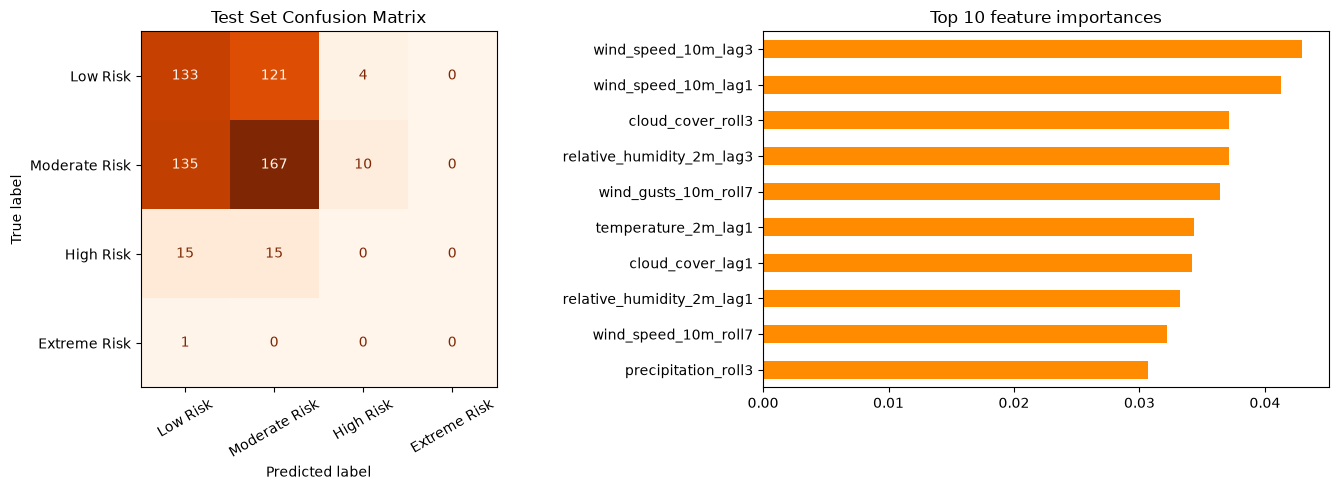


Top 10 features:
wind_speed_10m_lag3          0.042970
wind_speed_10m_lag1          0.041314
cloud_cover_roll3            0.037157
relative_humidity_2m_lag3    0.037136
wind_gusts_10m_roll7         0.036393
temperature_2m_lag1          0.034321
cloud_cover_lag1             0.034177
relative_humidity_2m_lag1    0.033239
wind_speed_10m_roll7         0.032188
precipitation_roll3          0.030688
dtype: float32


In [80]:
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

print("=== Training Set ===")
train_metrics = classification_full_report(y_train, y_train_pred, label="Train")
print("\n=== Validation Set ===")
val_metrics = classification_full_report(y_val, y_val_pred, label="Val")
print("\n=== Test Set ===")
test_metrics = classification_full_report(y_test, y_test_pred, label="Test")

# Confusion matrix on test set
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, y_test_pred, labels=class_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_label_names)
disp.plot(ax=ax[0], cmap="Oranges", colorbar=False)
ax[0].set_title("Test Set Confusion Matrix")
ax[0].tick_params(axis="x", rotation=30)

importances = pd.Series(model.feature_importances_, index=all_features_list).sort_values(ascending=False)
importances.head(10).plot(kind="barh", ax=ax[1], color="darkorange")
ax[1].invert_yaxis()
ax[1].set_title("Top 10 feature importances")

plt.tight_layout()
plt.show()

print("\nTop 10 features:")
print(importances.head(10))

### Experiment-1 did not give good results so we will proceed with more hyper tuning 

### EXPERIMENT-2

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit

In [81]:
model_params = {
    "n_estimators": 150,
    "max_depth": 2,
    "learning_rate": 0.03,
    "subsample": 0.7,
    "colsample_bytree": 0.6,
    "reg_lambda": 5,
    "min_child_weight": 5,
    "objective": "multi:softprob",
    "num_class": 4,
    "random_state": 42,
    "early_stopping_rounds": 15,
    "eval_metric": "mlogloss",
}
model_params

{'n_estimators': 150,
 'max_depth': 2,
 'learning_rate': 0.03,
 'subsample': 0.7,
 'colsample_bytree': 0.6,
 'reg_lambda': 5,
 'min_child_weight': 5,
 'objective': 'multi:softprob',
 'num_class': 4,
 'random_state': 42,
 'early_stopping_rounds': 15,
 'eval_metric': 'mlogloss'}

In [82]:
hyperparameters_selection_explanations = """
- n_estimators=150 + early_stopping_rounds=15: enough rounds to learn, with early stopping to prevent overfitting on a small training set.
- max_depth=2: very shallow trees, strongly limiting complexity given ~2,800 rows and severe class imbalance, where deep trees would easily 
  overfit to the handful of minority-class examples.
- learning_rate=0.03: low rate for a smoother, more conservative fit.
- subsample=0.7, colsample_bytree=0.6: adds randomness to reduce overfitting from the many correlated lag/rolling features.
- reg_lambda=5, min_child_weight=5: extra L2 regularization and a higher minimum child weight to further discourage the model from 
  fitting noise or overly specific splits driven by rare classes.
- objective='multi:softprob', num_class=4: configures XGBoost for multi-class probability output matching the 4 risk categories.
- eval_metric='mlogloss': monitors multi-class log loss during training/early stopping, which is sensitive to confident wrong 
  predictions - important given class imbalance.
- random_state=42: ensures reproducibility."""

In [83]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [84]:
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

model = XGBClassifier(**model_params)
model.fit(
    X_train, y_train,
    sample_weight=sample_weights,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

print(f"Best iteration: {model.best_iteration}")

Best iteration: 147


### J.4 Model Technical Performance

> Provide some explanations on model performance

=== Training Set ===
Train Macro F1:    0.497
Train Weighted F1: 0.560

Train Classification Report:
               precision    recall  f1-score   support

     Low Risk       0.64      0.55      0.59      1430
Moderate Risk       0.59      0.51      0.55      1256
    High Risk       0.17      0.77      0.28       108
 Extreme Risk       0.40      1.00      0.57         8

     accuracy                           0.54      2802
    macro avg       0.45      0.71      0.50      2802
 weighted avg       0.60      0.54      0.56      2802


=== Validation Set ===
Val Macro F1:    0.243
Val Weighted F1: 0.455

Val Classification Report:
               precision    recall  f1-score   support

     Low Risk       0.58      0.38      0.46       307
Moderate Risk       0.51      0.44      0.48       275
    High Risk       0.02      0.16      0.03        19
 Extreme Risk       0.00      0.00      0.00         0

     accuracy                           0.40       601
    macro avg       0.28  

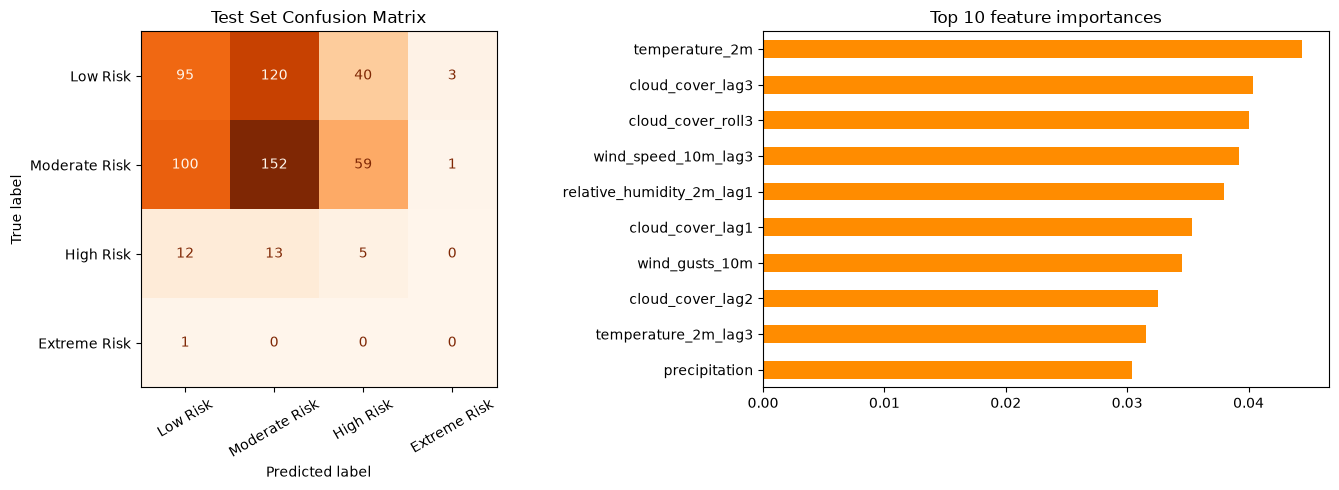


Top 10 features:
temperature_2m               0.044417
cloud_cover_lag3             0.040342
cloud_cover_roll3            0.040019
wind_speed_10m_lag3          0.039195
relative_humidity_2m_lag1    0.037941
cloud_cover_lag1             0.035325
wind_gusts_10m               0.034484
cloud_cover_lag2             0.032555
temperature_2m_lag3          0.031519
precipitation                0.030418
dtype: float32


In [85]:
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

print("=== Training Set ===")
train_metrics = classification_full_report(y_train, y_train_pred, label="Train")
print("\n=== Validation Set ===")
val_metrics = classification_full_report(y_val, y_val_pred, label="Val")
print("\n=== Test Set ===")
test_metrics = classification_full_report(y_test, y_test_pred, label="Test")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, y_test_pred, labels=class_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_label_names)
disp.plot(ax=ax[0], cmap="Oranges", colorbar=False)
ax[0].set_title("Test Set Confusion Matrix")
ax[0].tick_params(axis="x", rotation=30)

importances = pd.Series(model.feature_importances_, index=all_features_list).sort_values(ascending=False)
importances.head(10).plot(kind="barh", ax=ax[1], color="darkorange")
ax[1].invert_yaxis()
ax[1].set_title("Top 10 feature importances")

plt.tight_layout()
plt.show()

print("\nTop 10 features:")
print(importances.head(10))

In [86]:
model_performance_explanations = """
Results: Train Macro F1=0.497, Val Macro F1=0.243, Test Macro F1=0.248 (Weighted F1: Train=0.560, Val=0.455, Test=0.443).

The large drop from train to val/test Macro F1 indicates overfitting - the model performs much better on training data than on unseen periods, 
likely due to the high-dimensional feature set (42 features) relative to limited training examples, especially for minority classes.

Per-class breakdown (test set): Low Risk (F1=0.41) and Moderate Risk (F1=0.51) are predicted reasonably, but High Risk (F1=0.07) and 
Extreme Risk (F1=0.00) are essentially unlearned - the confusion matrix shows most High/Extreme Risk days misclassified as Low or 
Moderate Risk, confirming the model struggles badly on rare classes despite sample weighting.

Feature importance shows temperature_2m and cloud_cover-related lag/rolling features dominate, consistent with earlier feature selection 
results.

Overall, this model can distinguish Low vs Moderate Risk somewhat, but is not reliable for detecting High or Extreme Risk - the classes that 
matter most for a risk-warning use case - due to severe class imbalance and limited minority-class examples. This is a key limitation to flag 
for any business use."""

In [87]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view

In [88]:
test_results = pd.DataFrame({"actual": y_test.values, "predicted": y_test_pred})
test_results["ordinal_error"] = (test_results["predicted"] - test_results["actual"]).abs()

print("Distribution of ordinal prediction error (0 = exact match):")
print(test_results["ordinal_error"].value_counts().sort_index())

dangerous_misses = test_results[(test_results["actual"] >= 2) & (test_results["predicted"] == 0)]
print(f"\nDangerous misses (actual High/Extreme predicted as Low Risk): {len(dangerous_misses)}")
print(f"Out of {(test_results['actual'] >= 2).sum()} total actual High/Extreme Risk test days")

Distribution of ordinal prediction error (0 = exact match):
ordinal_error
0    252
1    292
2     53
3      4
Name: count, dtype: int64

Dangerous misses (actual High/Extreme predicted as Low Risk): 13
Out of 31 total actual High/Extreme Risk test days


In [89]:
import joblib
from pathlib import Path

models_dir = Path("../../models/weather_hazard")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, models_dir / "whc_xgboost_model.pkl")
joblib.dump(all_features_list, models_dir / "whc_feature_list.pkl")

print(f"Model saved to {models_dir / 'whc_xgboost_model.pkl'}")
print(f"Feature list saved ({len(all_features_list)} features)")

Model saved to ..\..\models\weather_hazard\whc_xgboost_model.pkl
Feature list saved (38 features)


In [90]:
business_impacts_explanations = """
Exact-match rate is only 252/601 (42%), with most errors off by 1 risk level (292 cases) - generally low business impact, as neighboring 
categories (e.g. Low vs Moderate) suggest similar action thresholds.

The critical issue: 13 out of 31 actual High/Extreme Risk days (42%) were predicted as Low Risk - a dangerous miss where the model fails to 
flag genuinely hazardous conditions as safe. This is the highest-impact error type, since it could lead to no precautions being taken (e.g. no 
warnings issued, no safety measures activated) during actual high-risk weather.

Business impact is asymmetric: a false alarm (predicting High Risk when actual is Low) is a minor cost (unnecessary caution), but missing 
a true High/Extreme Risk day (predicting Low Risk) could result in real harm or safety failures — and this model gets that wrong nearly 
half the time.

Given the model's near-zero recall on High/Extreme Risk classes and this ~42% dangerous miss rate, it should not be relied upon as a 
standalone safety/warning system. It may still offer some value for distinguishing Low vs Moderate Risk conditions, but any high-stakes 
decision-making should incorporate additional safeguards (e.g. lower decision thresholds for flagging risk, human review, or supplementary 
data sources) rather than trusting this model's risk classification alone.
"""

In [91]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [92]:
experiment_outcome = "Hypothesis Partially Confirmed" 

In [93]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [94]:
experiment_results_explanations = """
Weather features carry some signal for predicting risk category 7 days ahead (Test Macro F1=0.248), 
but the model fails badly on High/Extreme Risk, missing 13/31 (42%) actual dangerous days entirely.

Key insights:
- The best predictors are temperature_2m and cloud_cover-related lag/rolling features, which hold true for both feature selection techniques.
- The main bottleneck is severe class imbalance (Extreme Risk: 8 train / 0 val / 1 test example), which leaves the model with very few instances from which to learn uncommon, high-risk patterns.
- Overfitting on the high-dimensional artificial feature set in comparison to restricted data is indicated by the train-test F1 gap (0.497 vs. 0.248).

Rationale:
Although the existing method is insufficient for the highest-stakes classes (High/Extreme Risk) and cannot be used as is for safety-critical decisions, it is not a dead end for Low/Moderate Risk discrimination.

Next steps:
- Directly address class imbalance by using SMOTE, class-weighted loss tuning, or gathering more extreme-event data; the maximum uplift addresses the fundamental failure pattern.
- Incorporate non-weather characteristics (location, terrain, and previous incident data); a moderate uplift could help explain uncommon extreme occurrences.
"""

In [95]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)